# Fase 5 — Avaliação

**Projeto:** Supply Chain Forecasting — Rede Bandeirante · **Produto foco:** P0131

## Objetivo
Validar os modelos em **12 origens móveis** (espaçadas de 14 em 14 dias, a mesma cadência do
ciclo de reposição), terminando na última origem possível — **03/10/2019**. Em cada origem o
modelo observa apenas o passado e prevê os 28 dias seguintes. Uma única janela (Fase 4) não
basta para prometer desempenho a um comitê; o backtest mostra a estabilidade ao longo do ano.

Além da precisão, converte-se a previsão em **decisão de compra**:
- **Nível de serviço ótimo** (newsvendor) a partir dos custos de faltar (30% do preço) e sobrar (2%).
- **Estoque de segurança empírico** = quantil 93,75% dos erros de período do modelo.
- **Simulação de custo total por período** (pedido = previsão + estoque de segurança).

## Configuração do backtest
SARIMA e SARIMAX usam `trend=None` e `fit(method='powell', maxiter=200)` nesta fase.

## Resumo dos achados (média das 12 origens)
| Modelo | WMAPE médio | Viés global |
|---|---|---|
| Holt-Winters | 15,36% | +1,85% |
| SARIMAX+promo | 15,39% | +6,40% |
| Naive Sazonal | 16,15% | +0,58% |
| SARIMA | 18,18% | +7,44% |
| MM28 (baseline) | 22,05% | +6,12% |

Nível de serviço ótimo = **93,75%** (razão 15:1). Estoque de segurança: SARIMAX ≈ **783,6 un**;
Holt-Winters ≈ **1.484,2 un**; MM28 ≈ **2.111,9 un**. Custo por período: SARIMAX **R$ 107,04**;
MM28 **R$ 147,11**; Holt-Winters **R$ 160,13**. Economia anual do SARIMAX vs. processo atual ≈
**R$ 520,84**.

In [1]:
# ======================================================================
# 5.1 — Setup, carga e corte temporal
# ======================================================================

%matplotlib inline
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore")

# Caminhos relativos a raiz do projeto (localizada automaticamente)
from pathlib import Path


def _encontrar_raiz():
    """Sobe diretorios ate achar a raiz do projeto (que contem data/raw/demanda.csv)."""
    p = Path.cwd()
    for _ in range(6):
        if (p / "data" / "raw" / "demanda.csv").exists():
            return p
        p = p.parent
    return Path.cwd()


RAIZ = _encontrar_raiz()
CAMINHO_REDE = str(RAIZ / "data" / "raw" / "demanda.csv")
PASTA_FIGURAS = str(RAIZ / "reports" / "figures")
os.makedirs(PASTA_FIGURAS, exist_ok=True)
sns.set_theme(style="whitegrid", font_scale=1.05)

# --- Parametros do case ---
H = 28                                            # horizonte: lead time 14 + ciclo de revisao 14
PRODUTO_FOCO = "P0131"
PRODUTOS_REMOVER = ["P0438", "P0051", "P0079"]    # itens fora do escopo (regra da Fase 3)

# --- Carregamento e filtro (mesma regra da Fase 3) ---
df = pd.read_csv(CAMINHO_REDE, sep=",", parse_dates=["data"], dayfirst=False)
df_limpo = df[~df["produto"].isin(PRODUTOS_REMOVER)].copy().reset_index(drop=True)

serie_p = (
    df_limpo[df_limpo["produto"] == PRODUTO_FOCO]
    .sort_values("data")
    .set_index("data")
    .asfreq("D")
)

# --- Corte temporal: treino ate 03/10/2019; teste 04/10 a 31/10/2019 (28 dias) ---
data_maxima = serie_p.index.max()
data_corte = data_maxima - pd.Timedelta(days=H)
data_inicio_teste = data_corte + pd.Timedelta(days=1)
treino_p = serie_p.loc[:data_corte]
teste_p = serie_p.loc[data_inicio_teste:]

real = teste_p["unidades"].astype(float).values
indice_teste = teste_p.index
serie_treino_ord = treino_p.sort_index()["unidades"].astype(float)

print("FASE 5 — Avaliacao (backtest de origens moveis)  |  Produto {}".format(PRODUTO_FOCO))
print("=" * 78)
print("  Serie completa: {} -> {}".format(serie_p.index.min().date(), serie_p.index.max().date()))

FASE 5 — Avaliacao (backtest de origens moveis)  |  Produto P0131
  Serie completa: 2017-01-02 -> 2019-10-31


### 5.2 — Backtest de origens móveis
12 origens espaçadas de 14 em 14 dias; em cada origem prevê-se 28 dias à frente com os cinco
modelos. Guarda-se, por origem, o WMAPE e o erro do total do período (realizado − previsto).

In [2]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

N_ORIGENS = 12
ESPACAMENTO = 14
H_FCST = H  # 28

serie = serie_p["unidades"].astype(float)
exog = serie_p["pct_lojas_promo"].astype(float)

ultima_origem = serie.index.max() - pd.Timedelta(days=H_FCST)
origens = pd.date_range(end=ultima_origem, periods=N_ORIGENS, freq="{}D".format(ESPACAMENTO))
print("Primeira origem: {:%d/%m/%Y}  |  Ultima origem: {:%d/%m/%Y}".format(origens[0], origens[-1]))


def prever_naive(y, h):
    ult7 = y.iloc[-7:].values
    return np.tile(ult7, int(np.ceil(h / 7)))[:h]


def prever_mm28(y, h):
    return np.full(h, y.iloc[-28:].mean())


def prever_hw(y, h):
    m = ExponentialSmoothing(y, trend="add", seasonal="add", seasonal_periods=7,
                             initialization_method="estimated", freq="D").fit(optimized=True)
    return m.forecast(steps=h).values


def prever_sarima(y, h):
    m = SARIMAX(y, order=(2, 1, 2), seasonal_order=(1, 1, 1, 7), trend=None,
                enforce_stationarity=False, enforce_invertibility=False, freq="D")
    return m.fit(disp=False, method="powell", maxiter=200).forecast(steps=h).values


def prever_sarimax(y, ex_tr, h, ex_te):
    m = SARIMAX(y, exog=ex_tr, order=(2, 1, 2), seasonal_order=(1, 1, 1, 7), trend=None,
                enforce_stationarity=False, enforce_invertibility=False, freq="D")
    return m.fit(disp=False, method="powell", maxiter=200).forecast(steps=h, exog=ex_te).values


modelos = ["Naive Sazonal", "MM28", "Holt-Winters", "SARIMA", "SARIMAX+promo"]
resultados = []

for origem in origens:
    y_treino = serie.loc[:origem]
    ex_treino = exog.loc[:origem]
    ini = origem + pd.Timedelta(days=1)
    fim = origem + pd.Timedelta(days=H_FCST)
    real_o = serie.loc[ini:fim].values
    ex_teste = exog.loc[ini:fim]
    total_real = real_o.sum()

    prevs = {
        "Naive Sazonal": prever_naive(y_treino, H_FCST),
        "MM28": prever_mm28(y_treino, H_FCST),
        "Holt-Winters": prever_hw(y_treino, H_FCST),
        "SARIMA": prever_sarima(y_treino, H_FCST),
        "SARIMAX+promo": prever_sarimax(y_treino, ex_treino, H_FCST, ex_teste),
    }
    for nome in modelos:
        prev = np.clip(prevs[nome], 0, None)
        w = np.sum(np.abs(prev - real_o)) / total_real * 100
        erro = total_real - prev.sum()
        resultados.append([origem, nome, w, erro, prev.sum(), total_real])

df_res = pd.DataFrame(resultados, columns=[
    "origem", "modelo", "WMAPE", "erro_total_real_minus_prev", "total_previsto", "total_real"])
df_res["origem"] = pd.to_datetime(df_res["origem"])
print("Backtest concluido: {} linhas ({} origens x {} modelos)".format(len(df_res), N_ORIGENS, len(modelos)))

Primeira origem: 02/05/2019  |  Ultima origem: 03/10/2019


Backtest concluido: 60 linhas (12 origens x 5 modelos)


### 5.3 — Resumo por modelo (média das 12 origens)

In [3]:
resumo = df_res.groupby("modelo").agg(
    WMAPE_medio=("WMAPE", "mean"),
    WMAPE_std=("WMAPE", "std"),
    total_previsto=("total_previsto", "sum"),
    total_real=("total_real", "sum"),
).reindex(modelos)
resumo["Vies_global_%"] = (resumo["total_previsto"] - resumo["total_real"]) / resumo["total_real"] * 100

print("RESUMO POR MODELO — media das {} origens".format(N_ORIGENS))
print("=" * 78)
print("{:<16} | {:>12} | {:>10} | {:>12}".format("modelo", "WMAPE medio", "WMAPE std", "Vies global"))
print("-" * 78)
for nome in modelos:
    r = resumo.loc[nome]
    print("{:<16} | {:>11.2f}% | {:>9.2f}% | {:>+11.2f}%".format(
        nome, r["WMAPE_medio"], r["WMAPE_std"], r["Vies_global_%"]))

RESUMO POR MODELO — media das 12 origens
modelo           |  WMAPE medio |  WMAPE std |  Vies global
------------------------------------------------------------------------------
Naive Sazonal    |       16.15% |      8.34% |       +0.58%
MM28             |       22.05% |     11.56% |       +6.12%
Holt-Winters     |       15.36% |      9.81% |       +1.85%
SARIMA           |       18.18% |     16.35% |       +7.44%
SARIMAX+promo    |       15.39% |     13.34% |       +6.40%


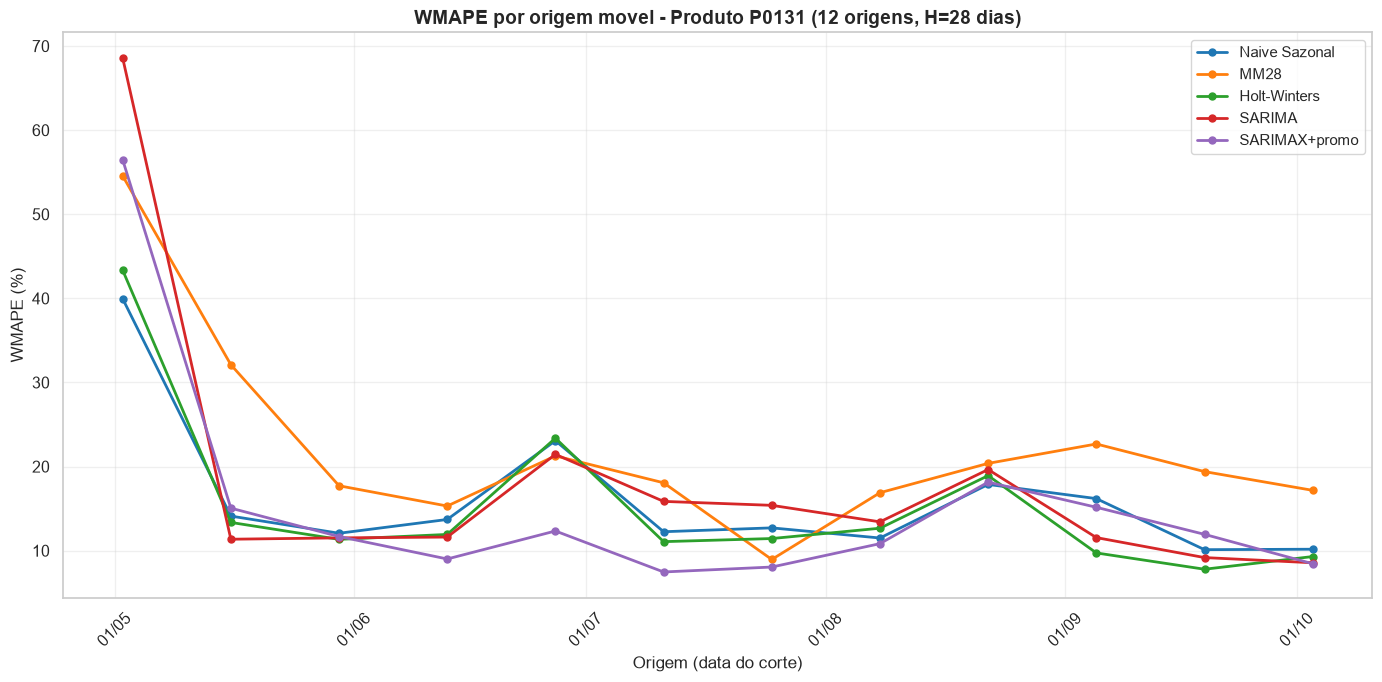

Figura salva em: C:\Users\flavi\Documents\GitHub\Supply-Chain-Forecasting\reports\figures\fase5_backtest_WMAPE_por_origem_P0131.png


In [4]:
# Grafico do WMAPE por origem movel
cores = {"Naive Sazonal": "#1f77b4", "MM28": "#ff7f0e", "Holt-Winters": "#2ca02c",
         "SARIMA": "#d62728", "SARIMAX+promo": "#9467bd"}
fig, ax = plt.subplots(figsize=(14, 7))
for nome in modelos:
    sub = df_res[df_res["modelo"] == nome].sort_values("origem")
    ax.plot(sub["origem"], sub["WMAPE"], marker="o", label=nome, color=cores[nome],
            linewidth=2, markersize=5)
ax.set_title("WMAPE por origem movel - Produto {} ({} origens, H={} dias)".format(
    PRODUTO_FOCO, N_ORIGENS, H_FCST), fontsize=14, fontweight="bold")
ax.set_xlabel("Origem (data do corte)")
ax.set_ylabel("WMAPE (%)")
ax.legend(loc="upper right", fontsize=11)
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
plt.xticks(rotation=45)
plt.tight_layout()
caminho_fig = os.path.join(PASTA_FIGURAS, "fase5_backtest_WMAPE_por_origem_{}.png".format(PRODUTO_FOCO))
plt.savefig(caminho_fig, dpi=150)
plt.show()
print("Figura salva em: {}".format(caminho_fig))

### 5.4 — Nível de serviço ótimo (newsvendor)
Faltar uma unidade custa ≈ 30% do preço; sobrar custa ≈ 2%. Com Cu = 0,30 × preço e
Co = 0,02 × preço, o nível de serviço que minimiza o custo esperado é Cu / (Cu + Co).

In [5]:
MARGEM_PERDIDA_PCT = 0.30   # custo de faltar (fração do preço)
CUSTO_CARREGO_PCT = 0.02    # custo de sobrar no período (fração do preço)

preco_medio = serie_p["preco_medio"].mean()
CU = MARGEM_PERDIDA_PCT * preco_medio          # custo de faltar uma unidade
CO = CUSTO_CARREGO_PCT * preco_medio           # custo de sobrar uma unidade
razao = CU / CO
NIVEL_SERVICO = CU / (CU + CO)

print("NIVEL DE SERVICO OTIMO — Produto {}".format(PRODUTO_FOCO))
print("=" * 70)
print("  Preco medio (P0131) ....... R$ {:.4f}".format(preco_medio))
print("  Cu = 0,30 x {:.4f} ......... R$ {:.4f}/un".format(preco_medio, CU))
print("  Co = 0,02 x {:.4f} ......... R$ {:.4f}/un".format(preco_medio, CO))
print("  Razao Cu/Co ............... {:.2f}x (faltar e {}x mais caro que sobrar)".format(razao, int(round(razao))))
print("  Nivel de servico otimo .... {:.6f} = {:.2f}%".format(NIVEL_SERVICO, NIVEL_SERVICO * 100))
print("  Prob. de ruptura aceita ... {:.2f}% por periodo".format((1 - NIVEL_SERVICO) * 100))
print("  >>> Pedir o quantil {:.2f}% da demanda, nao a media (que daria nivel ~50%).".format(NIVEL_SERVICO * 100))

NIVEL DE SERVICO OTIMO — Produto P0131
  Preco medio (P0131) ....... R$ 2.5870
  Cu = 0,30 x 2.5870 ......... R$ 0.7761/un
  Co = 0,02 x 2.5870 ......... R$ 0.0517/un
  Razao Cu/Co ............... 15.00x (faltar e 15x mais caro que sobrar)
  Nivel de servico otimo .... 0.937500 = 93.75%
  Prob. de ruptura aceita ... 6.25% por periodo
  >>> Pedir o quantil 93.75% da demanda, nao a media (que daria nivel ~50%).


### 5.5 — Estoque de segurança empírico
Em vez da fórmula normal, usa-se o **quantil 93,75% dos erros de período** do backtest
(erro = realizado − previsto). É o colchão que o modelo exige para atingir o nível de serviço.

In [6]:
def estoque_seguranca(erros, nivel=NIVEL_SERVICO):
    """Quantil empirico dos erros de periodo (realizado - previsto)."""
    return float(np.quantile(np.asarray(erros, dtype=float), nivel))

print("ESTOQUE DE SEGURANCA — quantil {:.2f}% dos erros do backtest".format(NIVEL_SERVICO * 100))
print("=" * 78)
for nome in ["Holt-Winters", "SARIMAX+promo", "MM28"]:
    erros = df_res.loc[df_res["modelo"] == nome, "erro_total_real_minus_prev"].values
    ss = estoque_seguranca(erros)
    pct_sem = np.mean(erros > 0) * 100
    pct_com = np.mean(erros > ss) * 100
    print("-" * 78)
    print("MODELO: {}".format(nome))
    print("  Erros de periodo ordenados: {}".format(np.round(np.sort(erros), 1).tolist()))
    print("  Estoque de seguranca ....... {:>10.1f} unidades".format(ss))
    print("  Faltaria pedindo so a previsao .......... {:>6.2f}% das origens".format(pct_sem))
    print("  Faltaria com o estoque de seguranca ..... {:>6.2f}% das origens".format(pct_com))

ESTOQUE DE SEGURANCA — quantil 93.75% dos erros do backtest
------------------------------------------------------------------------------
MODELO: Holt-Winters
  Erros de periodo ordenados: [-3366.2, -1655.1, -989.8, -951.4, -763.6, -29.3, 311.7, 421.6, 564.6, 848.3, 993.4, 2564.0]
  Estoque de seguranca .......     1484.2 unidades
  Faltaria pedindo so a previsao ..........  50.00% das origens
  Faltaria com o estoque de seguranca .....   8.33% das origens
------------------------------------------------------------------------------
MODELO: SARIMAX+promo
  Erros de periodo ordenados: [-4386.1, -1590.9, -983.1, -887.1, -688.0, -511.5, -133.2, -89.4, -25.4, 328.8, 547.6, 1302.8]
  Estoque de seguranca .......      783.6 unidades
  Faltaria pedindo so a previsao ..........  25.00% das origens
  Faltaria com o estoque de seguranca .....   8.33% das origens
------------------------------------------------------------------------------
MODELO: MM28
  Erros de periodo ordenados: [-4237.0, -

### 5.6 — Simulação de custo total por período
Pedido = previsão + estoque de segurança. Comparando com o realizado de cada origem:
`falta = max(0, erro − SS)` e `sobra = max(0, SS − erro)`. Custo = falta × Cu + sobra × Co.

In [7]:
PERIODOS_ANO = 13  # 13 ciclos de 28 dias por ano

def simular_custo(erros, nivel=NIVEL_SERVICO, cu=CU, co=CO):
    erros = np.asarray(erros, dtype=float)
    ss = float(np.quantile(erros, nivel))
    falta = np.maximum(0.0, erros - ss)
    sobra = np.maximum(0.0, ss - erros)
    return ss, float(np.mean(falta * cu + sobra * co)), float(np.mean(falta))

linhas = []
for nome in ["MM28", "Holt-Winters", "SARIMAX+promo"]:
    erros = df_res.loc[df_res["modelo"] == nome, "erro_total_real_minus_prev"].values
    ss, custo, falta = simular_custo(erros)
    linhas.append({"Modelo": nome, "Estoque_seguranca_un": ss,
                   "Custo_periodo_R$": custo, "Falta_media_un": falta})

res = pd.DataFrame(linhas).sort_values("Custo_periodo_R$").reset_index(drop=True)
print("SIMULACAO DE CUSTO TOTAL — P0131 (nivel {:.2f}%, Cu=R$ {:.4f}, Co=R$ {:.4f})".format(
    NIVEL_SERVICO * 100, CU, CO))
print("=" * 78)
print("{:<3} {:<16} {:>15} {:>16} {:>16}".format("#", "Modelo", "Est.Seg.(un)", "Custo/periodo", "Falta media(un)"))
print("-" * 78)
for i, r in res.iterrows():
    print("{:<3} {:<16} {:>15.1f} {:>16} {:>16.1f}".format(
        i + 1, r["Modelo"], r["Estoque_seguranca_un"],
        "R$ {:.2f}".format(r["Custo_periodo_R$"]), r["Falta_media_un"]))

SIMULACAO DE CUSTO TOTAL — P0131 (nivel 93.75%, Cu=R$ 0.7761, Co=R$ 0.0517)
#   Modelo              Est.Seg.(un)    Custo/periodo  Falta media(un)
------------------------------------------------------------------------------
1   SARIMAX+promo              783.6        R$ 107.04             43.3
2   MM28                      2111.9        R$ 147.11             10.3
3   Holt-Winters              1484.2        R$ 160.13             90.0


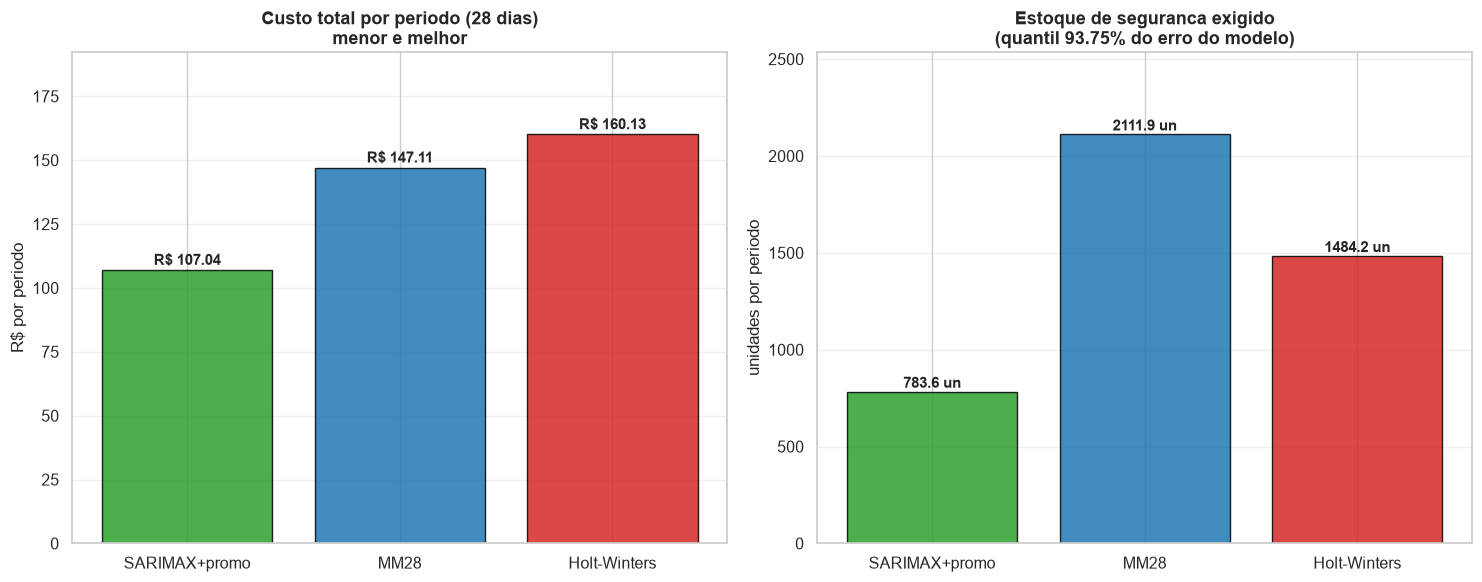

Figura salva em: C:\Users\flavi\Documents\GitHub\Supply-Chain-Forecasting\reports\figures\fase5_custo_estoque_seguranca_por_modelo.png


In [8]:
# Graficos: custo por periodo e estoque de seguranca
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
cores_barra = ["#2ca02c", "#1f77b4", "#d62728"]  # ja ordenado por custo
nomes = res["Modelo"].tolist()

b1 = ax1.bar(nomes, res["Custo_periodo_R$"], color=cores_barra, alpha=0.85, edgecolor="black")
ax1.set_title("Custo total por periodo (28 dias)\nmenor e melhor", fontsize=13, fontweight="bold")
ax1.set_ylabel("R$ por periodo")
ax1.grid(True, axis="y", alpha=0.3)
for b, v in zip(b1, res["Custo_periodo_R$"]):
    ax1.text(b.get_x() + b.get_width() / 2, v + 2, "R$ {:.2f}".format(v), ha="center",
             fontsize=11, fontweight="bold")
ax1.set_ylim(0, res["Custo_periodo_R$"].max() * 1.2)

b2 = ax2.bar(nomes, res["Estoque_seguranca_un"], color=cores_barra, alpha=0.85, edgecolor="black")
ax2.set_title("Estoque de seguranca exigido\n(quantil {:.2f}% do erro do modelo)".format(NIVEL_SERVICO * 100),
              fontsize=13, fontweight="bold")
ax2.set_ylabel("unidades por periodo")
ax2.grid(True, axis="y", alpha=0.3)
for b, v in zip(b2, res["Estoque_seguranca_un"]):
    ax2.text(b.get_x() + b.get_width() / 2, v + 20, "{:.1f} un".format(v), ha="center",
             fontsize=11, fontweight="bold")
ax2.set_ylim(0, res["Estoque_seguranca_un"].max() * 1.2)

plt.tight_layout()
caminho_fig = os.path.join(PASTA_FIGURAS, "fase5_custo_estoque_seguranca_por_modelo.png")
plt.savefig(caminho_fig, dpi=150)
plt.show()
print("Figura salva em: {}".format(caminho_fig))

### 5.7 — Comparação em reais com o processo atual (MM28)

In [9]:
base = res[res["Modelo"] == "MM28"].iloc[0]
print("COMPARACAO DIRETA COM O PROCESSO ATUAL (MM28)")
print("=" * 78)
for nome in ["SARIMAX+promo", "Holt-Winters"]:
    r = res[res["Modelo"] == nome].iloc[0]
    econ_periodo = base["Custo_periodo_R$"] - r["Custo_periodo_R$"]
    econ_ano = econ_periodo * PERIODOS_ANO
    var_pct = econ_periodo / base["Custo_periodo_R$"] * 100
    print("MODELO: {}".format(nome))
    print("  Custo por periodo: R$ {:.2f} -> R$ {:.2f}  (reducao de {:+.1f}%)".format(
        base["Custo_periodo_R$"], r["Custo_periodo_R$"], var_pct))
    print("  Estoque de seguranca: {:.1f} un -> {:.1f} un  ({:+.1f} un)".format(
        base["Estoque_seguranca_un"], r["Estoque_seguranca_un"],
        r["Estoque_seguranca_un"] - base["Estoque_seguranca_un"]))
    print("  ECONOMIA ANUAL ({} periodos): R$ {:,.2f} neste unico produto".format(PERIODOS_ANO, econ_ano))
    print()

COMPARACAO DIRETA COM O PROCESSO ATUAL (MM28)
MODELO: SARIMAX+promo
  Custo por periodo: R$ 147.11 -> R$ 107.04  (reducao de +27.2%)
  Estoque de seguranca: 2111.9 un -> 783.6 un  (-1328.3 un)
  ECONOMIA ANUAL (13 periodos): R$ 520.84 neste unico produto

MODELO: Holt-Winters
  Custo por periodo: R$ 147.11 -> R$ 160.13  (reducao de -8.9%)
  Estoque de seguranca: 2111.9 un -> 1484.2 un  (-627.7 un)
  ECONOMIA ANUAL (13 periodos): R$ -169.36 neste unico produto



## Conclusão da Fase 5
O backtest confirma a vantagem do SARIMAX+promo e do Holt-Winters sobre o baseline, e mostra
que o modelo precisa de **menos estoque de segurança** para o mesmo nível de serviço — o que
se traduz na menor **economia em reais**. O critério que manda (custo total) é atendido.